# Dataset A: NBA Salary Cap, Luxury Tax, and Apron Thresholds (2015-16 to 2025-26)

This dataset gives the league-wide dollar lines for each season: the salary cap, the luxury-tax line, and the first and second aprons. On its own it has only one row per season. Its job is to give the other two notebooks a reference point:

- **02 (llimllib salaries)** uses it to turn salaries into a **% of the salary cap** and to compute each team's **luxury-tax markers** and **dollars above/below each threshold**.
- **03 (ESPN contracts)** uses the cap to check which "minimum salary" contracts really are minimum-level.

*Run order: `01` → `02` → `03` → `999`. See [README.md](README.md).*

- **Dataset name:** `cap_tax_aprons.csv` from the Mr-Bridge *NBA Salary Cap & Contracts 2016-2026* dataset
- **Link:** https://huggingface.co/datasets/Mr-Bridge/nba-salary-cap-contracts-2016-2026
- **Saved as:** `data-files/00-raw/hf_cap_tax_aprons.csv` (downloaded below if missing)
- **Where the numbers come from:** the 2017 and 2023 NBA/NBPA collective bargaining agreements and the NBA's yearly cap announcements, cross-checked against Basketball-Reference and Spotrac (per the dataset's `source_status` column).

## Important variables

| Variable | Units | Meaning |
|---|---|---|
| `season_year` | year | The year the season **starts** (2015 = 2015-16). **Other notebooks use the end year, so we convert this.** |
| `season` | text | Season label, e.g. `2015-16` |
| `salary_cap` | USD (nominal) | The soft cap. A team under it can sign free agents outright. |
| `luxury_tax_line` | USD | Payroll above this line pays the luxury tax. |
| `first_apron` | USD | Under the 2023 CBA (from 2023-24), the first apron restricts trades and signings. Before that, this column holds the old "tax apron" (the hard-cap line that applied after certain moves), which is the closest equivalent. |
| `second_apron` | USD | Only exists from 2023-24 on. Teams above it face the strictest trade rules (e.g., they can't combine salaries in a trade). |

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from nba_cleaning_utils import RAW, PROCESSED, FIRST_SEASON, LAST_SEASON

pd.set_option('display.float_format', '{:,.0f}'.format)

## 1. Download (skipped if the file already exists) and load the data

In [2]:
import requests

RAW_CAP = RAW / 'hf_cap_tax_aprons.csv'
URL = 'https://huggingface.co/datasets/Mr-Bridge/nba-salary-cap-contracts-2016-2026/resolve/main/cap_tax_aprons.csv'
if not RAW_CAP.exists():
    r = requests.get(URL, timeout=60)
    r.raise_for_status()
    RAW_CAP.write_bytes(r.content)
    print('downloaded', RAW_CAP)

cap = pd.read_csv(RAW_CAP)
cap

downloaded ..\..\data-files\00-raw\hf_cap_tax_aprons.csv


,season_year,season,salary_cap,luxury_tax_line,first_apron,second_apron,source_status,notes
0,2015,2015-16,70000000,84740000,88740000,NaN,official/cross-check,Pre-spike baseline; old tax apron used as firs...
1,2016,2016-17,94143000,113287000,117287000,NaN,official/cross-check,2016 cap spike after national TV deal; old tax...
2,2017,2017-18,99093000,119266000,125266000,NaN,official/cross-check,2017 CBA season; tax apron/hard-cap line.
3,2018,2018-19,101869000,123733000,129817000,NaN,official/cross-check,Tax apron/hard-cap line.
4,2019,2019-20,109140000,132627000,138928000,NaN,official/cross-check,Tax apron/hard-cap line.
5,2020,2020-21,109140000,132627000,138928000,NaN,official/cross-check,COVID BRI shock; cap held flat.
6,2021,2021-22,112414000,136606000,143002000,NaN,official/cross-check,Tax apron/hard-cap line.
7,2022,2022-23,123655000,150267000,156983000,NaN,official/cross-check,Last pre-2023-CBA season; tax apron/hard-cap l...
8,2023,2023-24,136021000,165294000,172346000,"182,794,000",NBA official/cross-check,First season with first and second apron langu...
9,2024,2024-25,140588000,170814000,178132000,"188,931,000",NBA official/cross-check,2023 CBA apron regime fully visible in roster ...


## 2. Is the data tidy?

Tidy means one row per observation and one column per variable. The observation here is a season.

In [3]:
cap.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   season_year      12 non-null     int64  
 1   season           12 non-null     str    
 2   salary_cap       12 non-null     int64  
 3   luxury_tax_line  12 non-null     int64  
 4   first_apron      12 non-null     int64  
 5   second_apron     4 non-null      float64
 6   source_status    12 non-null     str    
 7   notes            12 non-null     str    
dtypes: float64(1), int64(4), str(3)
memory usage: 900.0 bytes


In [4]:
print('one row per season?', cap['season_year'].is_unique)

one row per season? True


**What we found:** The table is already tidy. Each row is one season and each money column is one threshold. The dollar columns load as numbers, and `second_apron` is a float only because it has blanks. No reshaping is needed.

## 3. Size of the data

In [5]:
print('rows, columns:', cap.shape)
print('seasons (start year):', cap['season_year'].min(), 'to', cap['season_year'].max())

rows, columns: (12, 8)
seasons (start year): 2015 to 2026


12 seasons, 2015-16 through 2026-27. Our project covers 2015-16 to 2025-26, so the 2026-27 row is one season past our range and will be dropped.

## 4. Missing data

In [6]:
cap.isna().sum()

season_year        0
season             0
salary_cap         0
luxury_tax_line    0
first_apron        0
second_apron       8
source_status      0
notes              0
dtype: int64

In [7]:
cap[['season', 'second_apron']]

,season,second_apron
0,2015-16,NaN
1,2016-17,NaN
2,2017-18,NaN
3,2018-19,NaN
4,2019-20,NaN
5,2020-21,NaN
6,2021-22,NaN
7,2022-23,NaN
8,2023-24,"182,794,000"
9,2024-25,"188,931,000"


**What we found:** Only `second_apron` has blanks, and they fall exactly in the seasons before 2023-24. **That is not missing data. The second apron didn't exist until the 2023 CBA.** We keep the blanks as `NaN` (XGBoost handles `NaN` natively) and add a `has_second_apron` flag, so later notebooks don't treat "no second apron" as "under the second apron".

## 5. Outliers and suspicious entries

The thresholds should always go in the same order: **cap < tax line < first apron < second apron**. They also shouldn't jump much from year to year, with one known exception, the 2016 cap spike from the new national TV deal.

In [8]:
in_order = (
    (cap['salary_cap'] < cap['luxury_tax_line'])
    & (cap['luxury_tax_line'] < cap['first_apron'])
    & (cap['second_apron'].isna() | (cap['first_apron'] < cap['second_apron']))
)
print('seasons where the thresholds are in the right order:', in_order.sum(), 'of', len(cap))

seasons where the thresholds are in the right order: 12 of 12


In [9]:
money = ['salary_cap', 'luxury_tax_line', 'first_apron', 'second_apron']
by_season = cap.set_index('season')[money]
growth = ((by_season / by_season.shift(1) - 1) * 100).round(1)
growth.columns = [c + ' % change' for c in money]
growth

,salary_cap % change,luxury_tax_line % change,first_apron % change,second_apron % change
season,,,,
2015-16,NaN,NaN,NaN,NaN
2016-17,34,34,32,NaN
2017-18,5,5,7,NaN
2018-19,3,4,4,NaN
2019-20,7,7,7,NaN
2020-21,0,0,0,NaN
2021-22,3,3,3,NaN
2022-23,10,10,10,NaN
2023-24,10,10,10,NaN


In [10]:
# How far apart are the lines, as a share of the cap?
by_season = cap.set_index('season')
gaps = pd.DataFrame({
    'tax line / cap': by_season['luxury_tax_line'] / by_season['salary_cap'],
    'first apron / cap': by_season['first_apron'] / by_season['salary_cap'],
    'second apron / cap': by_season['second_apron'] / by_season['salary_cap'],
})
pd.set_option('display.float_format', '{:,.3f}'.format)
gaps

,tax line / cap,first apron / cap,second apron / cap
season,,,
2015-16,1.211,1.268,NaN
2016-17,1.203,1.246,NaN
2017-18,1.204,1.264,NaN
2018-19,1.215,1.274,NaN
2019-20,1.215,1.273,NaN
2020-21,1.215,1.273,NaN
2021-22,1.215,1.272,NaN
2022-23,1.215,1.270,NaN
2023-24,1.215,1.267,1.344


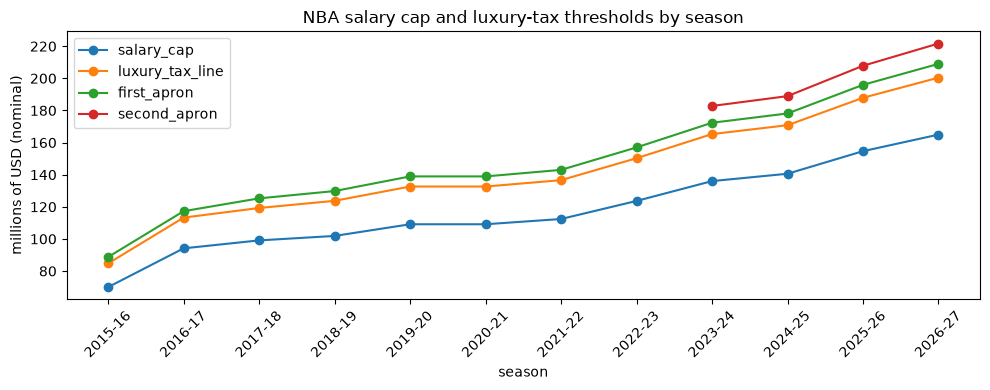

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for col in money:
    ax.plot(cap['season'], cap[col] / 1e6, marker='o', label=col)
ax.set_xlabel('season')
ax.set_ylabel('millions of USD (nominal)')
ax.set_title('NBA salary cap and luxury-tax thresholds by season')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
pd.set_option('display.float_format', '{:,.0f}'.format)

**What we found:**

- **The thresholds are always in the right order.**
- **The big jumps are real events, not errors.** The cap rose about 34% in 2016-17 (the new national TV deal), and was **0% in 2020-21** (the cap was held flat after COVID cut league revenue). Every other year moves by 1-10%.
- **The tax line sits at a steady 1.20-1.22x the cap** in every season, and the first apron at about 1.25-1.27x.
- **Dollar amounts are nominal.** The cap more than doubled over the decade (\$70M → \$155M), so a raw \$20M salary means very different things in 2016 and 2026. That's why the next notebook expresses salaries as a **% of the cap** instead of using raw or CPI-adjusted dollars.

Nothing needs to be removed.

## 6. Clean the data

1. Convert `season_year` (start year) to `season` (**end year**), the key every other notebook uses. 2015-16 becomes `2016`.
2. Keep only our project's seasons (2016 to 2026 in end years).
3. Add `has_second_apron`.
4. Drop the free-text `source_status` and `notes` columns. They document sources but are not model inputs.

In [12]:
cap_clean = (
    cap.rename(columns={'season': 'season_label'})
       .assign(season=lambda d: d['season_year'] + 1,
               has_second_apron=lambda d: d['second_apron'].notna())
       .query('@FIRST_SEASON <= season <= @LAST_SEASON')
       [['season', 'season_label', 'salary_cap', 'luxury_tax_line', 'first_apron', 'second_apron', 'has_second_apron']]
       .reset_index(drop=True)
)
for col in ['salary_cap', 'luxury_tax_line', 'first_apron']:
    cap_clean[col] = cap_clean[col].astype('int64')
cap_clean['second_apron'] = cap_clean['second_apron'].astype('Int64')   # nullable integer keeps the NaNs

cap_clean

,season,season_label,salary_cap,luxury_tax_line,first_apron,second_apron,has_second_apron
0,2016,2015-16,70000000,84740000,88740000,<NA>,False
1,2017,2016-17,94143000,113287000,117287000,<NA>,False
2,2018,2017-18,99093000,119266000,125266000,<NA>,False
3,2019,2018-19,101869000,123733000,129817000,<NA>,False
4,2020,2019-20,109140000,132627000,138928000,<NA>,False
5,2021,2020-21,109140000,132627000,138928000,<NA>,False
6,2022,2021-22,112414000,136606000,143002000,<NA>,False
7,2023,2022-23,123655000,150267000,156983000,<NA>,False
8,2024,2023-24,136021000,165294000,172346000,182794000,True
9,2025,2024-25,140588000,170814000,178132000,188931000,True


In [13]:
assert cap_clean['season'].is_unique
assert cap_clean['season'].min() == FIRST_SEASON and cap_clean['season'].max() == LAST_SEASON
cap_clean.dtypes

season              int64
season_label          str
salary_cap          int64
luxury_tax_line     int64
first_apron         int64
second_apron        Int64
has_second_apron     bool
dtype: object

## 7. Save

In [14]:
out = PROCESSED / 'cap_thresholds_clean.csv'
cap_clean.to_csv(out, index=False)
print('saved', cap_clean.shape, 'to', out)

saved (11, 7) to ..\..\data-files\02-processed\cap_thresholds_clean.csv


**Output:** `data-files/02-processed/cap_thresholds_clean.csv`, one row per season (end year 2016-2026), joined on `season`. Notebooks 02 and 03 read this file.